# Analisis de sentimientos con una CNN 1D

## 1. Descripcion del problema

El objetivo es clasificar las opiniones de clientes sobre restaurantes como positivas o negativas mediante una red neuronal convolucional unidimensional (CNN 1D).

El conjunto de datos contiene opiniones de Yelp escritas en ingles. Cada opinion tiene una etiqueta de sentimiento: 0 para negativo y 1 para positivo.

Se inspeccionaran y exploraran los datos, se prepararan los textos, se entrenara una CNN sencilla, se compararan algunas configuraciones de hiperparametros y se evaluara el modelo seleccionado con opiniones no utilizadas durante el entrenamiento.


## 2. Importacion de librerias


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dropout, Dense
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.callbacks import EarlyStopping

## 3. Inspeccion del conjunto de datos

El archivo contiene columnas separadas por tabulaciones y no tiene encabezados. La primera columna contiene la opinion y la segunda, su etiqueta.


In [2]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

df = pd.read_csv("yelp_labelled.txt", sep="\t", header=None, names=["review", "sentiment"])

In [4]:
print("Dataset dimensions:", df.shape)
print(df.info())
display(df.head())
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nLabels:", sorted(df["sentiment"].unique()))

Dataset dimensions: (1000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     1000 non-null   object
 1   sentiment  1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB
None


,review,sentiment
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1



Column types:
review       object
sentiment     int64
dtype: object

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 4

Labels: [0, 1]


## 4. Exploracion de los datos

Se examina la distribucion de las clases y la longitud de las opiniones.


Reviews per class:
sentiment
0    500
1    500
Name: count, dtype: int64


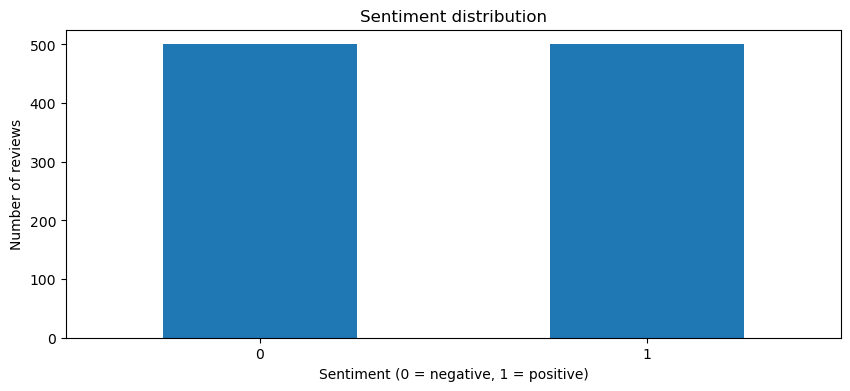

In [12]:
print("Reviews per class:")
print(df["sentiment"].value_counts().sort_index())

plt.figure(figsize=(10, 4))
df["sentiment"].value_counts().sort_index().plot(kind="bar")
plt.title("Sentiment distribution")
plt.xlabel("Sentiment (0 = negative, 1 = positive)")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

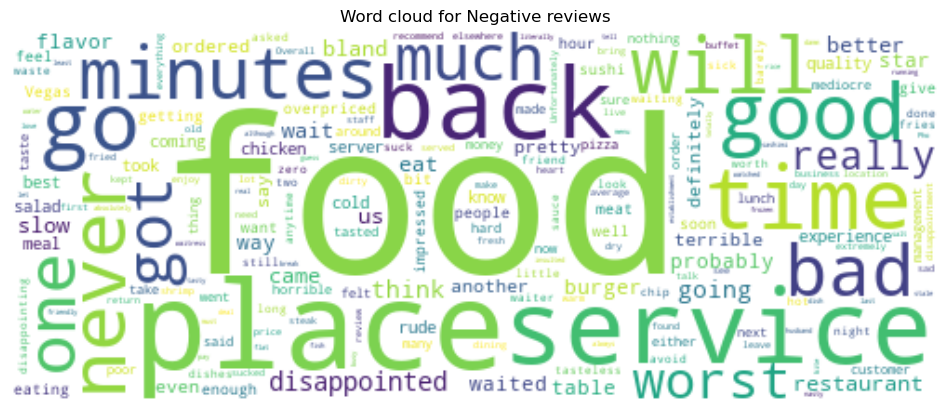

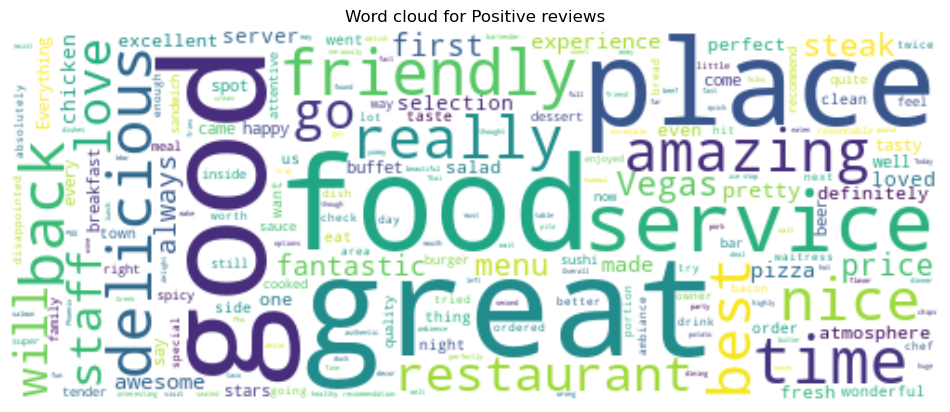

In [35]:
from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS)

for valor_sentimiento, nombre_categoria in [(0, "Negative"), (1, "Positive")]:
    texto_categoria = " ".join(df.loc[df["sentiment"] == valor_sentimiento, "review"].astype(str))
    nube = WordCloud(width=500, height=200, background_color="white", stopwords=stopwords, collocations=False).generate(texto_categoria)
    plt.figure(figsize=(12, 5))
    plt.imshow(nube, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word cloud for {nombre_categoria} reviews")
    plt.show()

Inspencción de valores duplicados y posibles ejemplos vacíos.

In [13]:
print("Number of duplicate reviews:", df["review"].duplicated().sum())
display(df[df["review"].duplicated(keep=False)].sort_values("review"))

Number of duplicate reviews: 4


,review,sentiment,word_count
334,I love this place.,1,4
814,I love this place.,1,4
380,I won't be back.,0,4
843,I won't be back.,0,4
505,I would not recommend this place.,0,6
846,I would not recommend this place.,0,6
383,The food was terrible.,0,4
816,The food was terrible.,0,4


In [15]:
print("Number of empty reviews:", df["review"].str.strip().eq("").sum())
display(df[df["review"].str.strip().eq("")])

Number of empty reviews: 0


,review,sentiment,word_count


## 5. Preparacion de los datos

Primero se eliminan las opiniones repetidas. Despues se dividen los datos en conjuntos de entrenamiento, validacion y prueba, manteniendo la proporcion de ambas clases.

TextVectorization convierte cada opinion en una secuencia de identificadores numericos de palabras. El vectorizador aprende su vocabulario utilizando solamente las opiniones de entrenamiento. Se utiliza una longitud maxima de 40 palabras por secuencia y un vocabulario de hasta 2000 tokens.

Se utiliza directamente el texto original porque TextVectorization ya aplica operaciones basicas de estandarizacion y tokenizacion.


In [14]:
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

In [19]:
X = df["review"].to_numpy()
y = df["sentiment"].to_numpy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Training: 697
Validation: 149
Test: 150


In [20]:
MAX_TOKENS = 2000
MAX_LENGTH = 40

vectorizer = TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LENGTH)
vectorizer.adapt(X_train)

X_train_seq = vectorizer(np.asarray(X_train)).numpy()
X_val_seq = vectorizer(np.asarray(X_val)).numpy()
X_test_seq = vectorizer(np.asarray(X_test)).numpy()

VOCAB_SIZE = len(vectorizer.get_vocabulary())

print("Vocabulary size:", VOCAB_SIZE)
print("Training matrix:", X_train_seq.shape)
print("Example review:", X_train[0])
print("Encoded review:", X_train_seq[0])

Vocabulary size: 1688
Training matrix: (697, 40)
Example review: Nice, spicy and tender.
Encoded review: [ 70 217   3 192   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0]


TextVectorization es una herramienta de Keras que permite transformar textos en secuencias numéricas para que puedan ser procesados por una red neuronal. Para ello, divide los textos en palabras, construye un vocabulario a partir del conjunto de entrenamiento y asigna un número entero (identificador) a cada palabra. Posteriormente, convierte cada texto en una secuencia de números de longitud fija, utilizando truncamiento o relleno con ceros cuando sea necesario.

Los identificadores numéricos se asignan principalmente según la frecuencia de aparición de las palabras en los textos de entrenamiento. Las palabras más frecuentes reciben identificadores enteros más bajos, mientras que las menos frecuentes reciben identificadores más altos.

## 6. Implementacion del modelo CNN

La capa Embedding representa las palabras mediante vectores numericos aprendidos. Conv1D identifica patrones locales en palabras consecutivas. GlobalMaxPooling1D conserva la caracteristica detectada mas destacada y la neurona final con activacion sigmoide estima la probabilidad de sentimiento positivo.

Se utiliza entropia cruzada binaria como funcion de perdida y Adam como optimizador.

In [21]:
def build_model(filters=32, kernel_size=3, dropout=0.3):
    model = Sequential([
        Input(shape=(MAX_LENGTH,)),
        Embedding(input_dim=VOCAB_SIZE, output_dim=32),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu"),
        GlobalMaxPooling1D(),
        Dropout(dropout),
        Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 40, 32)              │          54,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                      │ (None, 38, 32)              │           3,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling1d                 │ (None, 32)                  │               0 │
│ (GlobalMaxPooling1D)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 57,153 (223.25 KB)

 Trainable params: 57,153 (223.25 KB)

 Non-trainable params: 0 (0.00 B)

La capa Embedding de Keras transforma los identificadores numéricos de las palabras en vectores de números reales que se aprenden durante el entrenamiento de la red neuronal. A diferencia de TextVectorization, que asigna un número entero a cada palabra, Embedding representa cada palabra mediante un vector de varias dimensiones, cuyos valores se ajustan para capturar relaciones útiles entre las palabras según el problema que se está resolviendo. El procedimiento es:

1. TextVectorization construye el vocabulario utilizando las reseñas de entrenamiento y asigna un identificador a cada palabra.
2. Embedding crea una matriz de vectores, con una fila por cada identificador del vocabulario. Inicialmente, estos vectores contienen valores generados mediante un procedimiento de inicialización. El tamaño de cada vector lo define _output_dim_
3. Durante el entrenamiento de la CNN, los vectores se van ajustando a partir de los ejemplos y sus etiquetas de sentimiento, mediante retropropagación.

## 7. Experimentos con hiperparametros

Se comparan tres configuraciones sencillas de la CNN, modificando el numero de filtros convolucionales y el tamano del kernel. Todos los experimentos utilizan los mismos datos de entrenamiento y validacion, asi como el mismo criterio de parada.

EarlyStopping detiene el entrenamiento cuando la perdida de validacion deja de mejorar y restaura los mejores pesos. Se selecciona la configuracion con el mayor valor de F1 en validacion. Tambien se reporta la exactitud (accuracy).


In [36]:
configurations = [
    {"filters": 16, "kernel_size": 3, "dropout": 0.3},
    {"filters": 32, "kernel_size": 3, "dropout": 0.3},
    {"filters": 32, "kernel_size": 5, "dropout": 0.3}
]

results = []
models = []
histories = []

for i, config in enumerate(configurations):
    print("\nExperiment", i + 1, config)
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(**config)

    history = model.fit(X_train_seq, y_train, validation_data=(X_val_seq, y_val), epochs=20, batch_size=32, 
                        callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)], verbose=0)

    #val_prob = model.predict(X_val_seq, verbose=0).ravel()
    #y_prob = modelo(X_val, training=False).numpy().ravel()
    val_prob = model(X_val_seq, verbose=0).numpy().ravel()
    val_pred = (val_prob >= 0.5).astype(int)

    results.append({"experiment": i + 1, **config,
        "epochs": len(history.history["loss"]),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_f1": f1_score(y_val, val_pred)})
    models.append(model)
    histories.append(history)

results_df = pd.DataFrame(results).sort_values("val_f1", ascending=False)
display(results_df.round(4))


Experiment 1 {'filters': 16, 'kernel_size': 3, 'dropout': 0.3}


AttributeError: EagerTensor object has no attribute 'ravel'. 
        If you are looking for numpy-related methods, please run the following:
        tf.experimental.numpy.experimental_enable_numpy_behavior()
      

## 8. Seleccion del mejor modelo

La seleccion del modelo se realiza unicamente con los resultados de validacion. El conjunto de prueba no se ha utilizado para seleccionar los hiperparametros.


In [23]:
best_index = int(results_df.iloc[0]["experiment"]) - 1
best_model = models[best_index]
best_history = histories[best_index]

print("Selected experiment:", best_index + 1)
print("Configuration:", configurations[best_index])

Selected experiment: 1
Configuration: {'filters': 16, 'kernel_size': 3, 'dropout': 0.3}


## 9. Analisis de resultados

Primero se examinan las curvas de entrenamiento. Una diferencia considerable entre el rendimiento en entrenamiento y validacion puede indicar sobreajuste.


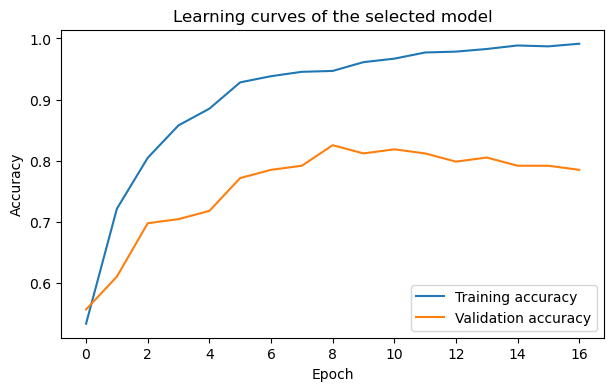

In [24]:
history_df = pd.DataFrame(best_history.history)

plt.figure(figsize=(7, 4))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Learning curves of the selected model")
plt.legend()
plt.show()

Se evalua el modelo seleccionado una sola vez sobre el conjunto de prueba. El reporte de clasificacion incluye precision, recall y F1 para cada clase.


Test accuracy: 0.82
Test F1 score: 0.8112

Classification report:
              precision    recall  f1-score   support

    Negative       0.79      0.87      0.83        75
    Positive       0.85      0.77      0.81        75

    accuracy                           0.82       150
   macro avg       0.82      0.82      0.82       150
weighted avg       0.82      0.82      0.82       150



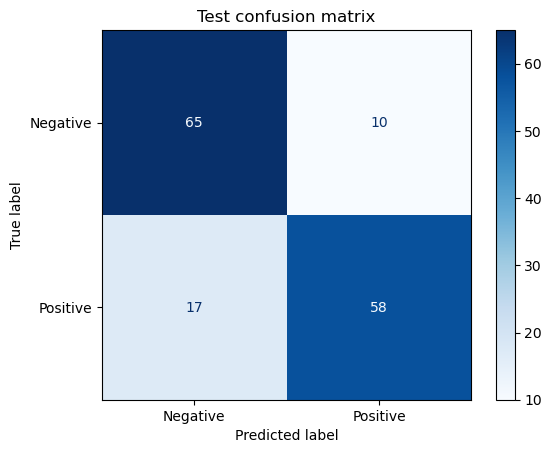

In [25]:
test_prob = best_model.predict(X_test_seq, verbose=0).ravel()
y_pred = (test_prob >= 0.5).astype(int)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test F1 score:", round(f1_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Negative", "Positive"], cmap="Blues"
)
plt.title("Test confusion matrix")
plt.show()

Se inspeccionan algunos errores para identificar los tipos de opiniones que resultan dificiles de clasificar para la CNN.


In [26]:
errors = pd.DataFrame({
    "review": X_test,
    "actual": y_test,
    "predicted": y_pred,
    "prob_positive": test_prob
})
errors = errors[errors["actual"] != errors["predicted"]]

print("Number of misclassified reviews:", len(errors))
display(errors.head(10))

Number of misclassified reviews: 27


,review,actual,predicted,prob_positive
4,You can't beat that.,1,0,0.093253
12,"OMG, the food was delicioso!",1,0,0.298221
20,What I really like there is the crepe station.,1,0,0.367114
22,"I don't each much pasta, but I love the homema...",1,0,0.233151
32,"Now the burgers aren't as good, the pizza whic...",0,1,0.926860
37,I miss it and wish they had one in Philadelphia!,1,0,0.466564
39,Will be back again!,1,0,0.438356
41,The chicken I got was definitely reheated and ...,0,1,0.588895
42,"Plus, it's only 8 bucks.",1,0,0.396126
50,I had high hopes for this place since the burg...,0,1,0.867074


## 10. Prediccion del sentimiento de nuevas opiniones

Una probabilidad mayor o igual a 0.5 se clasifica como positiva. Los textos nuevos deben transformarse utilizando el mismo vectorizador ajustado con los datos de entrenamiento.


In [28]:
new_reviews = np.array([
    "The food was delicious and the service was excellent.",
    "The food was cold and the service was terrible."
])

new_sequences = vectorizer(new_reviews)
new_prob = best_model.predict(new_sequences, verbose=0).ravel()

predictions = pd.DataFrame({
    "review": new_reviews,
    "prob_positive": new_prob,
    "predicted_sentiment": np.where(new_prob >= 0.5, "Positive", "Negative")
})
display(predictions)

,review,prob_positive,predicted_sentiment
0,The food was delicious and the service was exc...,0.996251,Positive
1,The food was cold and the service was terrible.,0.059782,Negative
